<a href="https://colab.research.google.com/github/GyangShady/GAN_Image_Generator/blob/main/GAN_Image_Gen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CIFAR-10 Image Generation with a Deep Convolutional GAN (DCGAN)
Cell 1 of 23
CIFAR-10 Image Generation with a Deep Convolutional GAN (DCGAN)
Author: Shedrach Gyang Emmanuel
Framework: PyTorch
Dataset: CIFAR-10
Environment: Google Colab / Jupyter Notebook

Project overview
This notebook implements a convolutional Generative Adversarial Network (GAN) that learns to generate 64 × 64 RGB images resembling samples from CIFAR-10.

A GAN contains two networks trained in competition:

Generator (G): maps random latent vectors to synthetic images.
Discriminator (D): estimates whether an input image is real or generated.
This is an improved, reproducible version of the original experiment. It retains the CIFAR-10 / PyTorch / DCGAN-style approach while adding clearer organization, epoch-level loss tracking, model initialization, checkpointing, and qualitative result visualization.

The notebook does not claim that generated images are photorealistic or that a particular quality score has been achieved. Run the experiment and interpret the outputs produced in your own runtime.

1. Experiment configuration
Cell 2 of 23
1. Experiment configuration
The default configuration is designed to be practical in a Colab GPU session. Increase NUM_EPOCHS for longer experiments after confirming that the first run completes successfully.

The model uses 64 × 64 images. CIFAR-10 images are originally 32 × 32 and are resized during preprocessing.

In [ ]:
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils

SEED = 42
DATA_DIR = "./data"
OUTPUT_DIR = Path("./outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
SAMPLE_DIR = OUTPUT_DIR / "samples"

NUM_EPOCHS = 25
BATCH_SIZE = 128
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100
LEARNING_RATE = 0.0002
BETA1 = 0.5
NUM_WORKERS = 2

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic settings improve repeatability, although exact reproducibility
# can still depend on the hardware, CUDA libraries, and PyTorch version.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Training epochs: {NUM_EPOCHS}")

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Training epochs: 25


Load and preprocess CIFAR-10
CIFAR-10 contains 60,000 colour images across 10 classes. The GAN is trained without using the class labels; only the images are needed.

The images are resized to 64 × 64 and normalized from [0, 1] to [-1, 1]. This range is compatible with the Generator's final Tanh activation.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

train_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

# drop_last=True ensures each training batch has the configured batch size,
# which is convenient for stable BatchNorm behaviour.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    drop_last=True,
    generator=loader_generator
)

print(f"Training images: {len(train_dataset):,}")
print(f"Batches per epoch: {len(train_loader):,}")

100%|██████████| 170M/170M [33:12<00:00, 85.6kB/s]


Training images: 50,000
Batches per epoch: 390


Define the Generator
The Generator receives a latent vector with 100 values and progressively upsamples it using transposed convolutions.

The final output has three channels and spatial dimensions of 64 × 64. Tanh constrains generated pixel values to approximately [-1, 1].

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, channels=CHANNELS):
        super().__init__()
        self.network = nn.Sequential(
            # (N, latent_dim, 1, 1) -> (N, 512, 4, 4)
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            # 4 -> 8
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # 8 -> 16
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 16 -> 32
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 32 -> 64
            nn.ConvTranspose2d(64, channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise):
        return self.network(noise)

Define the Discriminator
The Discriminator downsamples a 64 × 64 RGB image through convolutional layers and produces one probability-like score per image.

Because this implementation uses a final Sigmoid, the training objective uses BCELoss. The discriminator output is flattened to shape (batch_size,).

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, channels=CHANNELS):
        super().__init__()
        self.network = nn.Sequential(
            # (N, 3, 64, 64) -> (N, 64, 32, 32)
            nn.Conv2d(channels, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # 32 -> 16
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 16 -> 8
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # 8 -> 4
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # 4 -> 1
            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, images):
        return self.network(images).view(-1)

Initialize the models and verify tensor shapes
DCGAN-style weight initialization is used: convolution weights are sampled from a normal distribution with mean 0 and standard deviation 0.02; BatchNorm weights are initialized around 1.

In [ ]:
def initialize_weights(module):
    name = module.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)

G = Generator().to(device)
D = Discriminator().to(device)

G.apply(initialize_weights)
D.apply(initialize_weights)

# Shape test before training
test_noise = torch.randn(4, LATENT_DIM, 1, 1, device=device)
with torch.no_grad():
    test_images = G(test_noise)
    test_scores = D(test_images)

print("Generator output:", tuple(test_images.shape))
print("Discriminator output:", tuple(test_scores.shape))
print("Generated value range:",
      f"{test_images.min().item():.3f} to {test_images.max().item():.3f}")

assert test_images.shape == (4, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
assert test_scores.shape == (4,)

Generator output: (4, 3, 64, 64)
Discriminator output: (4,)
Generated value range: -0.866 to 0.817


Configure the GAN training process
The discriminator learns to classify real images as 1 and generated images as 0. The Generator learns to make generated images that the Discriminator classifies as real.

The training loop records the average loss across all batches in each epoch, rather than reporting only the final batch's loss.

During the Generator update, Discriminator parameters are temporarily frozen. Gradients still flow through the Discriminator operations to the generated images, allowing the Generator to learn without updating the Discriminator in that step.

In [ ]:
criterion = nn.BCELoss()

optimizer_G = optim.Adam(
    G.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)
optimizer_D = optim.Adam(
    D.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=device)

history = {
    "generator_loss": [],
    "discriminator_loss": []
}

Train the GAN
Training time depends on the available GPU, Colab session and data-loading performance. The default is 25 epochs; you can increase it for further experiments.

The notebook saves a generated image grid after each epoch and a checkpoint after training.

In [ ]:
def save_sample_grid(generator, epoch, noise=fixed_noise):
    generator.eval()
    with torch.no_grad():
        fake_images = generator(noise).detach().cpu()
    generator.train()

    grid = utils.make_grid(
        fake_images,
        nrow=8,
        normalize=True,
        value_range=(-1, 1)
    )
    output_path = SAMPLE_DIR / f"generated_epoch_{epoch:03d}.png"
    utils.save_image(grid, output_path)
    return output_path


start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    G.train()
    D.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for real_images, _ in train_loader:
        real_images = real_images.to(device, non_blocking=True)
        current_batch_size = real_images.size(0)

        real_targets = torch.ones(current_batch_size, device=device)
        fake_targets = torch.zeros(current_batch_size, device=device)

        # -------------------------
        # 1. Update Discriminator
        # -------------------------
        optimizer_D.zero_grad(set_to_none=True)

        real_predictions = D(real_images)
        d_real_loss = criterion(real_predictions, real_targets)

        noise = torch.randn(
            current_batch_size, LATENT_DIM, 1, 1, device=device
        )
        fake_images = G(noise)
        fake_predictions = D(fake_images.detach())
        d_fake_loss = criterion(fake_predictions, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # -------------------------
        # 2. Update Generator
        # -------------------------
        optimizer_G.zero_grad(set_to_none=True)

        for parameter in D.parameters():
            parameter.requires_grad_(False)

        generated_predictions = D(fake_images)
        g_loss = criterion(generated_predictions, real_targets)
        g_loss.backward()
        optimizer_G.step()

        for parameter in D.parameters():
            parameter.requires_grad_(True)

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    average_d_loss = total_d_loss / len(train_loader)
    average_g_loss = total_g_loss / len(train_loader)

    history["discriminator_loss"].append(average_d_loss)
    history["generator_loss"].append(average_g_loss)

    sample_path = save_sample_grid(G, epoch)

    print(
        f"Epoch [{epoch:03d}/{NUM_EPOCHS}] "
        f"D Loss: {average_d_loss:.4f} | "
        f"G Loss: {average_g_loss:.4f} | "
        f"Samples: {sample_path.name}"
    )

elapsed_minutes = (time.time() - start_time) / 60
print(f"\nTraining completed in {elapsed_minutes:.2f} minutes.")

Epoch [001/25] D Loss: 0.5285 | G Loss: 9.2741 | Samples: generated_epoch_001.png
Epoch [002/25] D Loss: 0.5846 | G Loss: 4.7250 | Samples: generated_epoch_002.png
Epoch [003/25] D Loss: 0.6297 | G Loss: 3.9744 | Samples: generated_epoch_003.png
Epoch [004/25] D Loss: 0.6466 | G Loss: 3.6108 | Samples: generated_epoch_004.png
Epoch [005/25] D Loss: 0.6634 | G Loss: 3.3691 | Samples: generated_epoch_005.png
Epoch [006/25] D Loss: 0.6959 | G Loss: 3.2304 | Samples: generated_epoch_006.png
Epoch [007/25] D Loss: 0.7196 | G Loss: 3.2019 | Samples: generated_epoch_007.png
Epoch [008/25] D Loss: 0.7696 | G Loss: 3.1580 | Samples: generated_epoch_008.png
Epoch [009/25] D Loss: 0.6471 | G Loss: 3.3906 | Samples: generated_epoch_009.png
Epoch [010/25] D Loss: 0.7773 | G Loss: 2.8074 | Samples: generated_epoch_010.png
Epoch [011/25] D Loss: 0.7528 | G Loss: 3.0686 | Samples: generated_epoch_011.png
Epoch [012/25] D Loss: 0.5893 | G Loss: 3.5104 | Samples: generated_epoch_012.png
Epoch [013/25] D

Plot training losses
GAN losses should be interpreted together with generated samples. A lower loss does not automatically mean that image quality is better; GAN training can be unstable and the two networks influence one another.

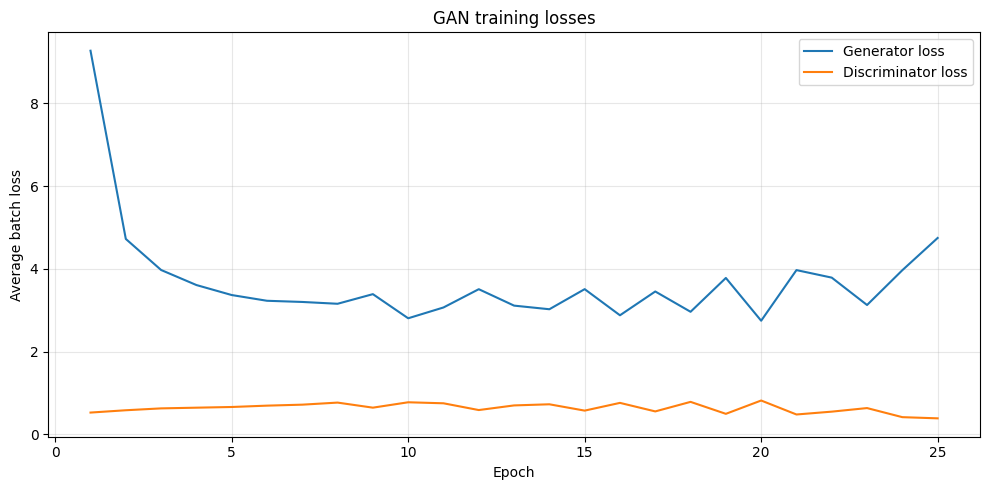

In [ ]:
epochs = range(1, len(history["generator_loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, history["generator_loss"], label="Generator loss")
plt.plot(epochs, history["discriminator_loss"], label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Average batch loss")
plt.title("GAN training losses")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Visualize generated images
The grid below uses the same fixed latent vectors each time it is generated. This makes it easier to visually compare how the Generator's outputs change during training.

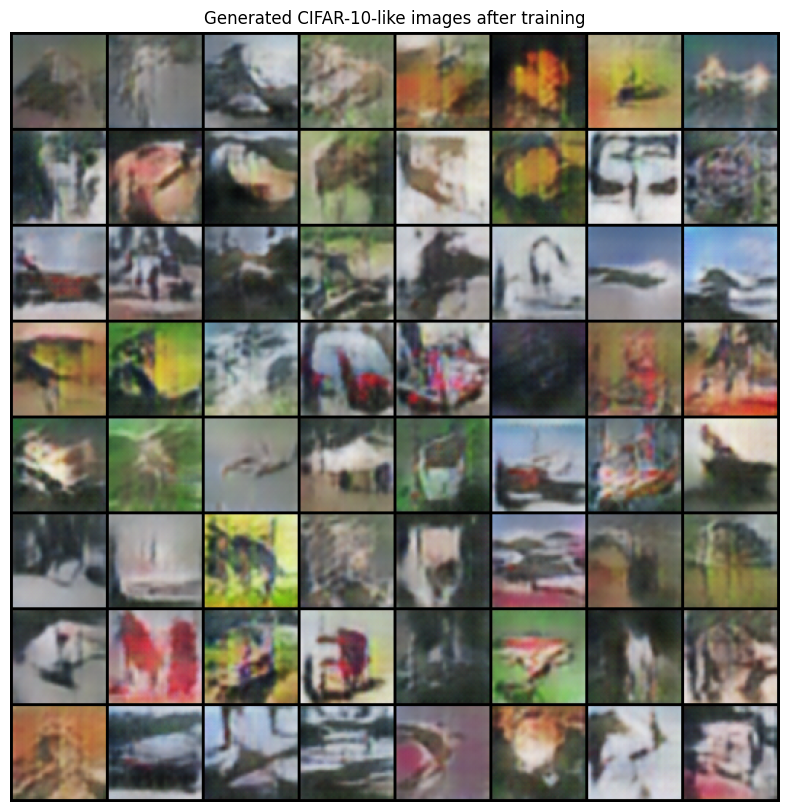

In [ ]:
G.eval()
with torch.no_grad():
    final_images = G(fixed_noise).cpu()

final_grid = utils.make_grid(
    final_images,
    nrow=8,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(10, 10))
plt.imshow(final_grid.permute(1, 2, 0).numpy())
plt.title("Generated CIFAR-10-like images after training")
plt.axis("off")
plt.show()

Save model checkpoints
The checkpoint stores model weights, optimizer states, experiment configuration and loss history so that the training run can be inspected or resumed.

In [ ]:
checkpoint = {
    "epoch": NUM_EPOCHS,
    "generator_state_dict": G.state_dict(),
    "discriminator_state_dict": D.state_dict(),
    "optimizer_G_state_dict": optimizer_G.state_dict(),
    "optimizer_D_state_dict": optimizer_D.state_dict(),
    "config": {
        "seed": SEED,
        "dataset": "CIFAR-10",
        "image_size": IMAGE_SIZE,
        "latent_dim": LATENT_DIM,
        "batch_size": BATCH_SIZE,
        "epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "beta1": BETA1
    },
    "history": history
}

checkpoint_path = CHECKPOINT_DIR / "dcgan_cifar10_checkpoint.pth"
torch.save(checkpoint, checkpoint_path)

print(f"Checkpoint saved to: {checkpoint_path}")
print(f"Sample images saved in: {SAMPLE_DIR.resolve()}")

Checkpoint saved to: outputs/checkpoints/dcgan_cifar10_checkpoint.pth
Sample images saved in: /content/outputs/samples


Experimental observations
Complete this section after running the notebook. Use your actual output rather than assuming that the model converged.

Consider documenting:
1. Did generated samples become more structured over the epochs?
2. Did the Generator or Discriminator loss show instability?
3. Were there signs of mode collapse (many generated samples looking very similar)?
4. What changed when you increased the number of epochs?
5. Which hyperparameters would you test next?
Limitations
- This is an unconditional GAN; CIFAR-10 class labels are not used.
- Training for a limited number of epochs may produce blurry or poorly defined images.
- Loss values alone are not a reliable measure of visual quality.
- No FID or Inception Score is calculated in this notebook.
- Results may vary with hardware, software versions and training settings.

Future experiments
Potential next experiments include:
- Compare 25, 50 and 100 epochs.
- Test different latent dimensions and learning rates.
- Compare the current architecture with a Wasserstein GAN with gradient penalty (WGAN-GP).
- Add quantitative evaluation such as Fréchet Inception Distance (FID), with a documented evaluation setup.
- Track and compare multiple runs using saved configurations and checkpoints.

Conclusion
This project implements a PyTorch DCGAN-style model for unconditional image generation using CIFAR-10. It demonstrates dataset preprocessing, convolutional neural network design, adversarial optimization, training diagnostics, visualization and checkpointing.

The quality of the generated images and the stability of training should be assessed from the outputs produced by the executed experiment.